# 05 — Fine-tuned ResNet-18 (Model B)

This notebook launches the project study-level fine-tuning implementation. Each study can include several views. Real views are aggregated at study level and padded views are masked.

Only the internal train and validation populations are used. The official MURA valid split is not read.

In [ ]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Published output snapshot

Model B was selected at validation epoch 9; the curve is shown below.

In [1]:
# Training summary from the completed validation-only fine-tuning run.
import pandas as pd
training_summary = pd.DataFrame([
    {'Item': 'Best validation epoch', 'Value': '9'},
    {'Item': 'Epochs completed', 'Value': '13 (early stopping)'},
    {'Item': 'Checkpoint selection', 'Value': 'Validation AUROC, pre-specified mean pooling'},
    {'Item': 'Operating policy', 'Value': 'Highest validation threshold at 95% sensitivity'},
    {'Item': 'Official MURA valid/test read', 'Value': 'No'},
])
display(training_summary)

Item,Value
Best validation epoch,9
Epochs completed,13 (early stopping)
Checkpoint selection,"Validation AUROC, pre-specified mean pooling"
Operating policy,Highest validation threshold at 95% sensitivity
Official MURA valid/test read,No


In [1]:
# Aggregate Model B metrics from the completed development run.
from pathlib import Path
import pandas as pd
comparison = pd.read_csv(Path('../docs/results/checkpoint1/model_comparison.csv'))
comparison = comparison.loc[comparison['model'].eq('Fine-tuned ResNet-18 mean pooling')].copy()
target = float(comparison['sensitivity_target'].iloc[0])
policy_label = f'Sensitivity @ >={target:.0%} policy'
specificity_label = f'Specificity @ >={target:.0%} policy'
columns = ['model', 'auroc', 'auprc', 'sensitivity_at_target', 'specificity_at_target', 'false_negative_at_target', 'false_positive_at_target', 'flagged_percent_at_target']
notebook_summary = comparison[columns].rename(columns={
    'model': 'Model', 'auroc': 'AUROC', 'auprc': 'AUPRC',
    'sensitivity_at_target': policy_label,
    'specificity_at_target': specificity_label,
    'false_negative_at_target': 'False negatives',
    'false_positive_at_target': 'False positives',
    'flagged_percent_at_target': 'Flagged for review (%)',
})
for column in ['AUROC', 'AUPRC', policy_label, specificity_label, 'Flagged for review (%)']:
    notebook_summary[column] = notebook_summary[column].round(3)
display(notebook_summary)

Model,AUROC,AUPRC,Sensitivity @ >=95% policy,Specificity @ >=95% policy,False negatives,False positives,Flagged for review (%)
Fine-tuned ResNet-18 mean pooling,0.913,0.878,0.952,0.583,13,176,62.518


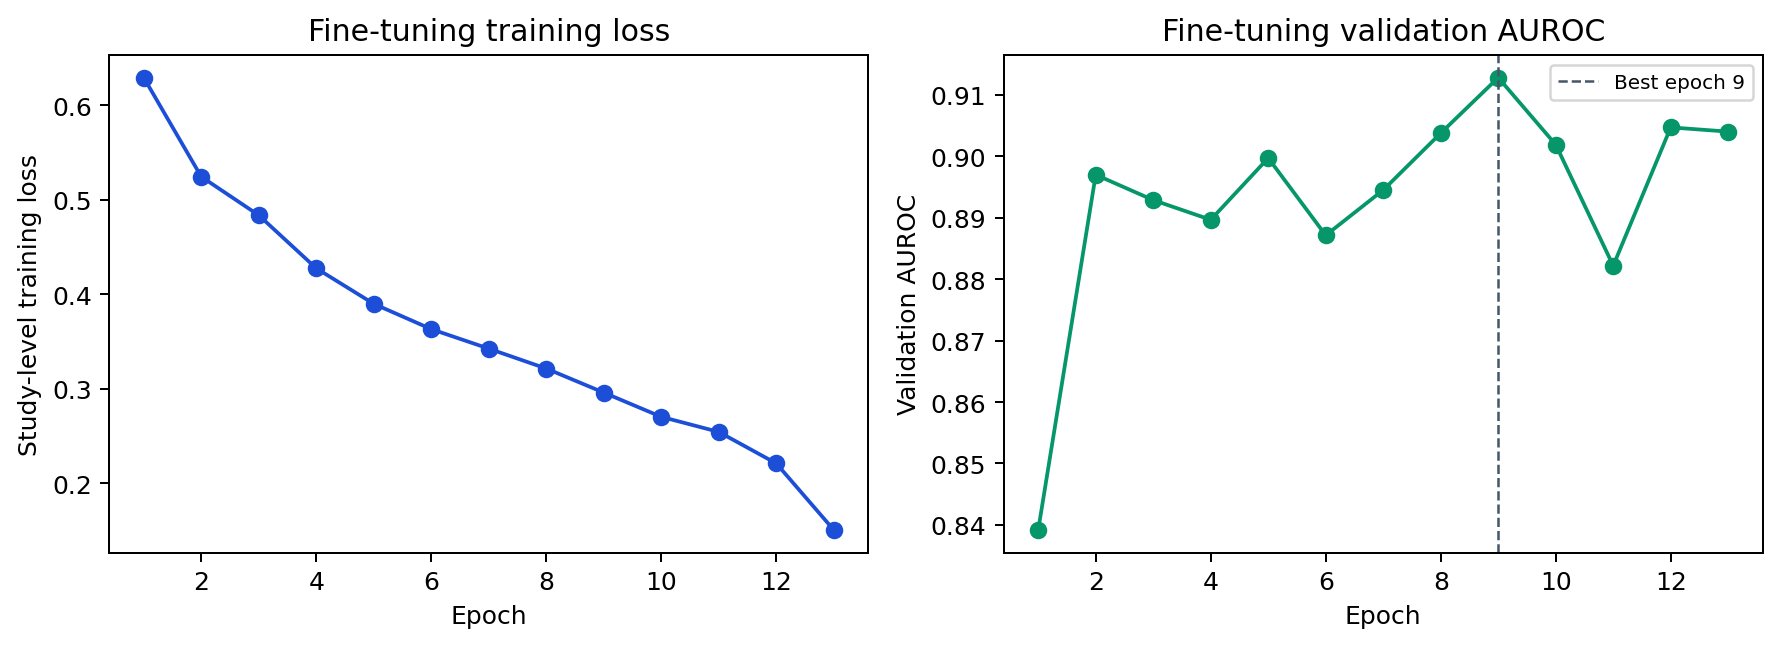

In [1]:
# Training loss and validation AUROC over epochs.
from IPython.display import Image, display
display(Image(filename='../docs/results/checkpoint1/finetuning_history.png'))

## Project and data paths

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ModuleNotFoundError:
    pass

PROJECT_ROOT = Path(os.environ.get(
    "MURA_PROJECT_ROOT",
    "/content/drive/MyDrive/MURA_PROJECT/mura-wrist-ml-pipeline",
))
DATA_ROOT = Path(os.environ.get(
    "MURA_DATA_ROOT",
    "/content/drive/MyDrive/DATA/MURA-v1.1",
))
PREPROCESSING_DIR = Path(os.environ.get(
    "MURA_PREPROCESSING_DIR",
    "/content/drive/MyDrive/DATA/PREPROCESSED_WRIST",
))
ARTIFACT_DIR = Path(os.environ.get(
    "MURA_MODEL_B_DIR",
    "/content/drive/MyDrive/DATA/MODEL_B_FINE_TUNING",
))
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_B_INPUT_DIR = ARTIFACT_DIR / "model_b_input"
MODEL_B_INPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_SCRIPT = PROJECT_ROOT / "scripts/train_resnet18.py"
for required_path in (
    PREPROCESSING_DIR / "wrist_internal_train_clean.csv",
    PREPROCESSING_DIR / "wrist_internal_val_clean.csv",
    TRAIN_SCRIPT,
    DATA_ROOT / "train",
):
    assert required_path.exists(), f"Not found: {required_path}"

print({"project_root": str(PROJECT_ROOT), "data_root": str(DATA_ROOT), "artifact_dir": str(ARTIFACT_DIR)})

## Build Model B inputs from the cleaned Model A split

In [ ]:
train_clean = pd.read_csv(PREPROCESSING_DIR / "wrist_internal_train_clean.csv")
validation_clean = pd.read_csv(PREPROCESSING_DIR / "wrist_internal_val_clean.csv")
PATH_CANDIDATES = ("file_name", "image_path", "relative_path", "path")
PATH_COLUMN = next((name for name in PATH_CANDIDATES if name in train_clean.columns), None)
assert PATH_COLUMN is not None and PATH_COLUMN in validation_clean.columns

def make_model_b_rows(frame, final_split):
    result = frame[["patient_id", "study_uid", PATH_COLUMN, "label_binary"]].copy()
    result["image_path"] = result[PATH_COLUMN].astype(str).str.replace("\\", "/", regex=False)
    result["image_path"] = result["image_path"].str.split("MURA-v1.1/", n=1).str[-1]
    result = result.rename(columns={"study_uid": "study_id", "label_binary": "label"})
    result["source_split"] = "train"
    result["final_split"] = final_split
    result["num_views_in_study"] = result.groupby("study_id")["image_path"].transform("size")
    return result[["patient_id", "study_id", "image_path", "label", "source_split", "num_views_in_study", "final_split"]]

model_b_rows = pd.concat([
    make_model_b_rows(train_clean, "train"),
    make_model_b_rows(validation_clean, "val"),
], ignore_index=True)
assert model_b_rows.groupby("study_id")["label"].nunique().max() == 1
assert set(model_b_rows.loc[model_b_rows.final_split.eq("train"), "patient_id"]).isdisjoint(
    set(model_b_rows.loc[model_b_rows.final_split.eq("val"), "patient_id"])
)

MODEL_B_MANIFEST = MODEL_B_INPUT_DIR / "wrist_clean_manifest.csv"
MODEL_B_SPLIT = MODEL_B_INPUT_DIR / "wrist_clean_split_manifest.csv"
model_b_rows.drop(columns="final_split").to_csv(MODEL_B_MANIFEST, index=False)
model_b_rows[["patient_id", "study_id", "final_split"]].drop_duplicates().to_csv(MODEL_B_SPLIT, index=False)
print({"train_studies": int((model_b_rows.final_split == "train").groupby(model_b_rows.study_id).max().sum()), "validation_studies": int((model_b_rows.final_split == "val").groupby(model_b_rows.study_id).max().sum())})

## Frozen training recipe

In [ ]:
TRAINING_RECIPE = {
    "architecture": "ImageNet ResNet-18 with one logit per view",
    "loss": "weighted BCE on the study-level mean probability",
    "train_split": "internal patient-level train",
    "validation_split": "internal patient-level validation",
    "official_valid_access": False,
    "epochs": 15,
    "batch_size_studies": 2,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "early_stopping": "validation study AUROC, patience 4",
    "preprocessing": "grayscale, square black padding, 224x224 bilinear resize, ImageNet normalization",
    "augmentation": "rotation up to 7 degrees, brightness 0.08, contrast 0.10; no horizontal flip or crop",
    "primary_aggregation": "mean probability (pre-specified before training)",
    "secondary_aggregation": "max probability (diagnostic only; not selected post hoc)",
    "operating_policy": "highest validation threshold with sensitivity >= 95%",
}
display(pd.DataFrame([TRAINING_RECIPE]))


## Run fine-tuning without test access

In [ ]:
command = [
    sys.executable,
    str(TRAIN_SCRIPT),
    "--manifest", str(MODEL_B_MANIFEST),
    "--split-manifest", str(MODEL_B_SPLIT),
    "--dataset-root", str(DATA_ROOT),
    "--output-dir", str(ARTIFACT_DIR),
    "--epochs", "15",
    "--batch-size", "2",
    "--workers", "0",
    "--learning-rate", "1e-4",
    "--weight-decay", "1e-4",
    "--early-stopping-patience", "4",
    "--seed", "42",
    "--device", "auto",
    "--weights", "imagenet",
    "--class-weighting", "auto",
    "--monitor-metric", "auroc",
    "--train-aggregation", "mean",
    "--monitor-aggregation", "mean",
    "--sensitivity-target", "0.95",
    "--scheduler", "plateau",
    "--bootstrap-samples", "1000",
]
print(" ".join(command))
subprocess.run(command, cwd=PROJECT_ROOT, check=True)

## Inspect saved development artifacts

In [ ]:
required_outputs = [
    "best_resnet18_study_level.pt",
    "training_history.json",
    "validation_metrics.json",
    "validation_predictions.csv",
    "validation_predictions_mean.csv",
    "validation_predictions_max.csv",
    "selection.json",
    "run_config.json",
]
for name in required_outputs:
    assert (ARTIFACT_DIR / name).exists(), f"Training did not produce: {name}"

history = json.loads((ARTIFACT_DIR / "training_history.json").read_text(encoding="utf-8"))
validation_metrics = json.loads((ARTIFACT_DIR / "validation_metrics.json").read_text(encoding="utf-8"))
selection = json.loads((ARTIFACT_DIR / "selection.json").read_text(encoding="utf-8"))
run_config = json.loads((ARTIFACT_DIR / "run_config.json").read_text(encoding="utf-8"))
validation_predictions = pd.read_csv(ARTIFACT_DIR / "validation_predictions.csv")

assert run_config["arguments"]["write_test_predictions"] is False
assert selection["test_used_for_selection"] is False
assert selection["selection_data"] == "validation only"
assert validation_predictions["split"].eq("validation").all()
assert validation_predictions["study_id"].is_unique

# This saved checkpoint predates the 95% protocol update. Reuse its saved mean-pooled
# validation probabilities, but do not reuse its historical Youden-J threshold.
PRIMARY_SENSITIVITY_TARGET = 0.95
policy_rows = []
labels = validation_predictions["label"].to_numpy(dtype=int)
scores = validation_predictions["abnormal_probability"].to_numpy(dtype=float)
for threshold in np.unique(scores)[::-1]:
    predicted = scores >= threshold
    true_positive = int(((labels == 1) & predicted).sum())
    false_negative = int(((labels == 1) & ~predicted).sum())
    true_negative = int(((labels == 0) & ~predicted).sum())
    false_positive = int(((labels == 0) & predicted).sum())
    sensitivity = true_positive / (true_positive + false_negative)
    if sensitivity >= PRIMARY_SENSITIVITY_TARGET:
        policy_rows.append({
            "threshold": float(threshold),
            "sensitivity": float(sensitivity),
            "specificity": float(true_negative / (true_negative + false_positive)),
            "true_positive": true_positive,
            "false_negative": false_negative,
            "true_negative": true_negative,
            "false_positive": false_positive,
        })

if not policy_rows:
    raise RuntimeError("No internal-validation threshold reached the pre-specified sensitivity target.")
primary_policy = sorted(policy_rows, key=lambda row: (row["threshold"], row["specificity"]), reverse=True)[0]
frozen_policy = {
    "model": "Fine-tuned ResNet-18",
    "study_aggregation": "mean_probability",
    "source_split": "internal_validation",
    "selection_rule": "highest threshold with sensitivity >= target",
    "target_sensitivity": PRIMARY_SENSITIVITY_TARGET,
    "test_used_for_selection": False,
    **primary_policy,
}
(ARTIFACT_DIR / "frozen_primary_operating_policy.json").write_text(
    json.dumps(frozen_policy, indent=2), encoding="utf-8"
)

display(pd.DataFrame(history["history"]))
display(pd.DataFrame([frozen_policy]))


## Training diagnostics

In [ ]:
history_frame = pd.DataFrame(history["history"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_frame["epoch"], history_frame["train_loss"], marker="o")
axes[0].set(title="Study-level training loss", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=0.3)

axes[1].plot(history_frame["epoch"], history_frame["validation_monitor"], marker="o")
best_epoch = int(history["best_epoch"])
axes[1].axvline(best_epoch, color="tab:green", linestyle="--", label=f"best epoch = {best_epoch}")
axes[1].set(title="Internal-validation study AUROC", xlabel="Epoch", ylabel="AUROC")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Handoff

Notebook 06 compares Model B with the frozen embedding baseline on the same internal-validation studies. It does not create a new official-valid result.